In [1]:
from mayavi import mlab
import pandas as pd
import numpy as np
import os, random, string
import nibabel as nb
from matplotlib import pyplot as plt
import matplotlib
from scipy.ndimage import distance_transform_edt
from matplotlib.colors import ListedColormap
import matplotlib.colors as mcolors
from matplotlib.ticker import FuncFormatter
from mpl_toolkits.mplot3d import Axes3D
from skimage.measure import label, regionprops

from tqdm import trange

QStandardPaths: error creating runtime directory '/run/user/7335' (Read-only file system)


********************************************************************************
         to build the TVTK classes (9.2). This may cause problems.
         Please rebuild TVTK.
********************************************************************************



In [2]:
def load_nifti(src: str):
    """
    Load nifti image. Array is rearranged so that it aligns with TIFF or HDF5 format.
    Parameters
    ----------
    src : str
    """
    stack = nb.load(src).get_fdata()
    # the below line is needed to make it consistent with TIFF array order
    stack = np.swapaxes(stack, 0, 2)
    return stack

In [3]:
atlas_path='/bucket/ReiterU/DBS/atlas/S_lessoniana_OL_v0.4/segmentation/atlas_seg10.nii.gz'
atlas=load_nifti(atlas_path)
masked_atlas=np.copy(atlas)
dt1,dt1_indexes = distance_transform_edt(atlas != 3.,return_indices=True) 
masked_dt1=dt1[masked_atlas==0]=np.nan
masked_atlas[masked_atlas==0]=np.nan

In [4]:
with open('DG_EXP_NAMES.txt', 'r') as f:
    EXP_NAMES = [line.strip() for line in f if line.strip()]

In [5]:
gen_path='/bucket/ReiterU/electrophysiology/squidOL/'


In [6]:
rec_paths=[]
for exp_name in EXP_NAMES:
    rec_list=os.listdir(gen_path+exp_name)
    found=False
    for i in rec_list:
        if 'STAB_CHECK' in i:
            rec_paths.append(gen_path+exp_name+'/'+i)
            found=True
            break
    if found==False:
        print('not found in {}'.format(exp_name))

In [7]:
dataset_ids=[]
ALL_spikes=[]
ALL_ids=[]
ALL_channels=[]
probe_data=[]
for rec in range(len(rec_paths)):
    rec_path = rec_paths[rec]
    exp_path = gen_path + EXP_NAMES[rec]
    post_path = rec_path + '/post_processed/'
    for probe in os.listdir(post_path):
        if len(os.listdir(post_path + '/' + probe)) != 0:
            sort_path = post_path + '/' + probe + '/'
            dataset_ids.append(EXP_NAMES[rec] + '_' + probe)

            spike_t_matrix = np.load(sort_path + '/spike_t_matrix.npy', allow_pickle=True)
            g_channels = np.load(sort_path + '/g_channels.npy')
            g_ids = np.load(sort_path + '/g_ids.npy')

            ALL_spikes.append(spike_t_matrix)
            ALL_ids.append(g_ids)
            ALL_channels.append(g_channels)

            # Check for both possible probe_skeleton filenames
            if probe == 'probe1':
                probe_path = exp_path + '/probe_skeleton/probe_2_transformed.csv'
            elif probe == 'probe0':
                probe_path = exp_path + '/probe_skeleton/probe_1_transformed.csv'
            probe_data.append(probe_path)

In [8]:
probes = []
names= []
probe_chan_regions=[]
for d in probe_data:
    df = pd.read_csv(d)
    df = df.loc[50:] # crop extrapolated channels
    zyx = df[["Z","Y","X"]].to_numpy()
    chan_reg=df[['Region']].to_numpy()
    probes.append(zyx)
    probe_chan_regions.append(chan_reg)


probe_colors = [matplotlib.colors.to_rgb(c) for c in plt.cm.get_cmap('tab20', len(probes)+1).colors]
probe_colors = tuple(probe_colors)
probes_smooth=[(np.asarray(probe)/10).astype(int) for probe in probes] # /10 to match the atlas indexes.

/scratch/ipykernel_995302/4235932017.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  probe_colors = [matplotlib.colors.to_rgb(c) for c in plt.cm.get_cmap('tab20', len(probes)+1).colors]


In [9]:
# Append coordinates to list of matrices. The shape matches all previous created lists : Number_of_probes X number_of_units_on_probe
ALL_UNIT_COORDS=[] # Real coordinates
ALL_UNIT_SMOOTH_COORDS=[] # Atlas index coordinates
for data_index in range(len(dataset_ids)):
    UNIT_COORDS=[]
    UNIT_SMOOTH_COORDS=[]
    g_ids=ALL_ids[data_index]
    g_channels=ALL_channels[data_index]

    for unit in range(len(g_ids)):
        unit_channel=g_channels[unit]
        chan_coords=probes[data_index][unit_channel]
        chan_smooth_coords=probes_smooth[data_index][unit_channel]
        UNIT_COORDS.append(chan_coords)
        UNIT_SMOOTH_COORDS.append(chan_smooth_coords)
    ALL_UNIT_COORDS.append(np.asarray(UNIT_COORDS))
    ALL_UNIT_SMOOTH_COORDS.append(np.asarray(UNIT_SMOOTH_COORDS))

In [10]:
DATASET_DIRs=np.load('/home/k/k-tsaridis/SQUID_EPHYS/VISION_PAPER_SUPP/DATASET_DIRs.npy',allow_pickle=True)
DATASET_ORIs=np.load('/home/k/k-tsaridis/SQUID_EPHYS/VISION_PAPER_SUPP/DATASET_ORIs.npy',allow_pickle=True)
DATASET_gDSIs=np.load('/home/k/k-tsaridis/SQUID_EPHYS/VISION_PAPER_SUPP/DATASET_GDSIs.npy',allow_pickle=True)
DATASET_gOSIs=np.load('/home/k/k-tsaridis/SQUID_EPHYS/VISION_PAPER_SUPP/DATASET_GOSIs.npy',allow_pickle=True)
DATASET_DSI_Ps=np.load('/home/k/k-tsaridis/SQUID_EPHYS/VISION_PAPER_SUPP/DATASET_DSI_Ps.npy',allow_pickle=True)
DATASET_OSI_Ps=np.load('/home/k/k-tsaridis/SQUID_EPHYS/VISION_PAPER_SUPP/DATASET_OSI_Ps.npy',allow_pickle=True)


In [13]:
### Plot all neuron channel scatterplot ###
mlab.figure(size=(150,150), bgcolor=(1, 1, 1)) 

regions = ["IGL", "MED", "OGL", "PD", "PXL", "CB"]
colors = (
    (0.96,0.50,0.10),
    (0.50,0.18,0.70),
    (0.031, 0.188, 0.420),
    (0.35,0.45,1.00),
    (0.2,0.8,0.2),
    (0.90,0.07,0.04)
)

for r, c in zip(regions, colors):
    d = mlab.pipeline.open(f"/bucket/ReiterU/DBS/atlas/S_lessoniana_OL_v0.4/segmentation/{r}.ply")
    mlab.pipeline.surface(d, color=c, opacity=0.05)

for data_index in range(len(dataset_ids)):
    g_ids = ALL_ids[data_index]
    UNIT_COORDS = ALL_UNIT_COORDS[data_index]
    for unit in range(len(g_ids)):
        if l1[data_index][unit]==1:
            the_color=(1,0,0)
        else:
            the_color=(0,0,0)
        mlab.points3d(UNIT_COORDS[unit,2], UNIT_COORDS[unit,1], UNIT_COORDS[unit,0], color=the_color,scale_factor=50)

# View angles
# mlab.view(180, 180, 10000, focalpoint=(1500, 2500, 1000))  # coronal
mlab.view(0, 90, 10000, focalpoint=(1500, 2200, 2000), roll=180)  # sagittal
# mlab.view(90, 270, 10000, focalpoint=(1500, 2200, 1500), roll=0)  # horizontal

# Save high-res figure
mlab.savefig(save_path+"neuron_scatter_highres.png",magnification=8)

mlab.close(all=True)


In [45]:
ALL_UNIT_DISTS=[]
ALL_UNIT_SEGS=[]
for data_index in range(len(dataset_ids)):
    UNIT_DIST=[]
    UNIT_SEGS=[]
    g_ids=ALL_ids[data_index]
    for unit in range(len(g_ids)):
        z,y,x=ALL_UNIT_SMOOTH_COORDS[data_index][unit][0],ALL_UNIT_SMOOTH_COORDS[data_index][unit][1],ALL_UNIT_SMOOTH_COORDS[data_index][unit][2]
        seg=masked_atlas[z][y][x]
        unit_dist=dt1[z][y][x]
        UNIT_DIST.append(unit_dist)
        UNIT_SEGS.append(seg)

    ALL_UNIT_DISTS.append(np.asarray(UNIT_DIST))
    ALL_UNIT_SEGS.append(np.asarray(UNIT_SEGS))
ALL_UNIT_DISTS=np.asarray(ALL_UNIT_DISTS,dtype='object')
ALL_UNIT_SEGS=np.asarray(ALL_UNIT_SEGS,dtype='object')

In [46]:
SEG_LABELS=['MEDULLA','PED','OGL','PLEX','IGL','CB']
sort_order=[2,3,4,0,1,5]

In [52]:
FLAT_UNIT_DISTS=np.concatenate(ALL_UNIT_DISTS)
FLAT_DSI_Ps=np.concatenate(DATASET_DSI_Ps)
FLAT_UNIT_SEGS=np.concatenate(ALL_UNIT_SEGS)
FLAT_UNIT_DISTS=FLAT_UNIT_DISTS+10 #OGL

In [53]:
pass_unit_dists=FLAT_UNIT_DISTS[FLAT_DSI_Ps>0.95]
pass_unit_segs=FLAT_UNIT_SEGS[FLAT_DSI_Ps>0.95]

In [54]:
bin_size=20
bins=np.arange(0,np.nanmax(FLAT_UNIT_DISTS)+bin_size,bin_size)
all_hist,_=np.histogram(FLAT_UNIT_DISTS,bins)
pass_hist,_=np.histogram(pass_unit_dists,bins)

In [58]:
plt.figure(figsize=(4/2.54,3/2.54))
ax=plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.bar(bins[:-1],pass_hist/all_hist,width=bin_size-(bin_size)/10,color='black')
plt.ylabel('% DS Units')
plt.xlabel('Distance (mm)')
plt.xticks([0,40,80,120],[0,0.4,0.8,1.2])
plt.ylim([0,0.3])
plt.yticks([0,0.15,0.3],[0,15,30])
plt.tight_layout()
#plt.savefig(save_path+'DS_UNIT_PROPORTION_over_distance.svg',format='svg',dpi=600)
#plt.show()
plt.close()

In [32]:
pass_seg_dist=[]
seg_dist=[]
for i in range(1,7):
    x=np.count_nonzero(pass_unit_segs==i)
    y=np.count_nonzero(FLAT_UNIT_SEGS==i)
    pass_seg_dist.append(x)
    seg_dist.append(y)

In [40]:
SEG_RATIOS=np.asarray(pass_seg_dist)/np.asarray(seg_dist)
reordered_seg_ratios=SEG_RATIOS[sort_order]


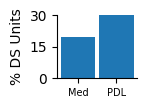

In [44]:
SEG_LABELS=['OGL','Plex','IGL','Med','PDL','CB']

plt.figure(figsize=(4/2.54,3/2.54))
ax=plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.bar(range(len(SEG_RATIOS[3:5])), reordered_seg_ratios[3:5],width=0.9)

# Add labels to the bars
plt.xticks(range(len(SEG_RATIOS[3:5])), SEG_LABELS[3:5],fontsize=7)
plt.ylim([0,0.3])
plt.yticks([0,0.15,0.3],[0,15,30])
# Show the plot
plt.ylabel('% DS Units')
plt.tight_layout()
#plt.savefig(save_path+'DSI_dist_over_atlas.svg',format='svg',dpi=600)
plt.show()
#plt.close()